# Import lIbraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import PoissonRegressor

# Laod dataset and Preprocess

In [3]:
df = pd.read_csv(
    "data/sri-lanka-daily-port-activity-data-and-shipment-estimates.csv",
    parse_dates=["date"]
)

In [4]:
df.shape

(11020, 29)

In [5]:
df.head(5)

,date,year,month,day,portid,portname,country,ISO3,portcalls_container,portcalls_dry_bulk,...,import_tanker,import_cargo,import,export_container,export_dry_bulk,export_general_cargo,export_roro,export_tanker,export_cargo,export
0,2026-07-17 00:00:00+00:00,2026,7,17,port254,Colombo,Sri Lanka,LKA,7,2,...,9174,65539,74714,33511,2413,2947,0,1542,38872,40415
1,2026-07-17 00:00:00+00:00,2026,7,17,port678,Hambantota,Sri Lanka,LKA,0,0,...,0,8384,8384,0,0,1963,723,0,2687,2687
2,2026-07-17 00:00:00+00:00,2026,7,17,port1319,Trincomalee,Sri Lanka,LKA,0,0,...,0,0,0,0,0,0,0,0,0,0
3,2026-07-17 00:00:00+00:00,2026,7,17,port2224,Galle,Sri Lanka,LKA,0,0,...,0,0,0,0,0,0,0,0,0,0
4,2026-07-16 00:00:00+00:00,2026,7,16,port254,Colombo,Sri Lanka,LKA,12,1,...,0,83392,83392,83558,250,9032,0,0,92842,92842


In [6]:
# filtering the dataframe to only include rows where the portname is "Colombo"
df = df[df["portname"] == "Colombo"].copy()

In [7]:
df.head()

,date,year,month,day,portid,portname,country,ISO3,portcalls_container,portcalls_dry_bulk,...,import_tanker,import_cargo,import,export_container,export_dry_bulk,export_general_cargo,export_roro,export_tanker,export_cargo,export
0,2026-07-17 00:00:00+00:00,2026,7,17,port254,Colombo,Sri Lanka,LKA,7,2,...,9174,65539,74714,33511,2413,2947,0,1542,38872,40415
4,2026-07-16 00:00:00+00:00,2026,7,16,port254,Colombo,Sri Lanka,LKA,12,1,...,0,83392,83392,83558,250,9032,0,0,92842,92842
8,2026-07-15 00:00:00+00:00,2026,7,15,port254,Colombo,Sri Lanka,LKA,10,1,...,0,59136,59136,22734,1611,0,0,0,24346,24346
12,2026-07-14 00:00:00+00:00,2026,7,14,port254,Colombo,Sri Lanka,LKA,9,0,...,9174,46276,55450,7243,0,1814,0,1542,9058,10601
16,2026-07-13 00:00:00+00:00,2026,7,13,port254,Colombo,Sri Lanka,LKA,9,0,...,22962,18467,41430,44657,0,0,0,2689,44657,47346


In [8]:
# sort the dataframe by date in ascending order
df = df.sort_values("date")

In [9]:
df.shape

(2755, 29)

In [10]:
df.isnull().sum()

date                       0
year                       0
month                      0
day                        0
portid                     0
portname                   0
country                    0
ISO3                       0
portcalls_container        0
portcalls_dry_bulk         0
portcalls_general_cargo    0
portcalls_roro             0
portcalls_tanker           0
portcalls_cargo            0
portcalls                  0
import_container           0
import_dry_bulk            0
import_general_cargo       0
import_roro                0
import_tanker              0
import_cargo               0
import                     0
export_container           0
export_dry_bulk            0
export_general_cargo       0
export_roro                0
export_tanker              0
export_cargo               0
export                     0
dtype: int64

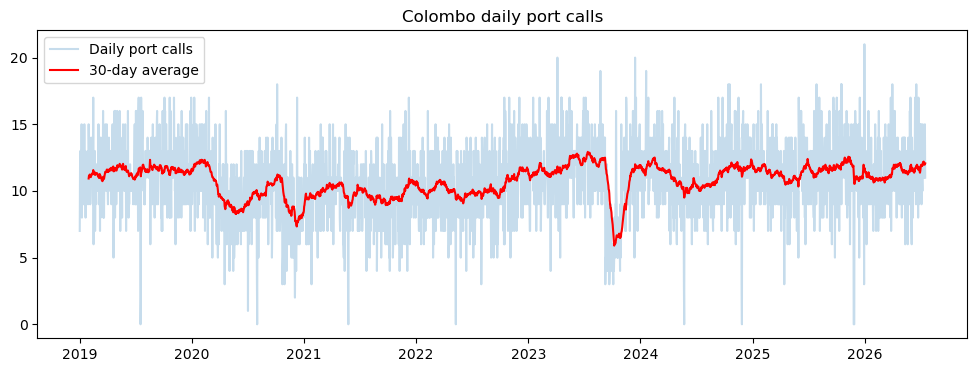

In [11]:
df["visual_avg_30"] = df["portcalls"].rolling(30).mean()
plt.figure(figsize=(12, 4))
plt.plot(df["date"], df["portcalls"], alpha=0.25, label="Daily port calls")
plt.plot(df["date"], df["visual_avg_30"], color="red", label="30-day average")
plt.title("Colombo daily port calls")
plt.legend()
plt.show()

In [12]:
df["lag_1"] = df["portcalls"].shift(1)
df["lag_7"] = df["portcalls"].shift(7)
df["avg_7"] = df["portcalls"].shift(1).rolling(7).mean()
df["month"] = df["date"].dt.month

features = ["lag_1", "lag_7", "avg_7", "month"]
data = df.dropna(subset=features).copy()
display(data[["date", "portcalls"] + features].head())

,date,portcalls,lag_1,lag_7,avg_7,month
10988,2019-01-08 00:00:00+00:00,8,15.0,7.0,11.142857,1
10984,2019-01-09 00:00:00+00:00,12,8.0,12.0,11.285714,1
10980,2019-01-10 00:00:00+00:00,13,12.0,13.0,11.285714,1
10976,2019-01-11 00:00:00+00:00,9,13.0,9.0,11.285714,1
10972,2019-01-12 00:00:00+00:00,13,9.0,13.0,11.285714,1


Train on dates before 2024; select regularization on 2024; evaluate once on 2025 onward.

In [13]:
train = data[data["date"] < "2024-01-01"]
valid = data[(data["date"] >= "2024-01-01") & (data["date"] < "2025-01-01")]
test = data[data["date"] >= "2025-01-01"]
print("Train:", len(train), "Validation:", len(valid), "Test:", len(test))

Train: 1819 Validation: 366 Test: 563


In [14]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import PoissonRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

results = []
for alpha in [0.01, 0.1, 1, 10, 100]:
    candidate = make_pipeline(StandardScaler(), PoissonRegressor(alpha=alpha, max_iter=1000))
    candidate.fit(train[features], train["portcalls"])
    pred = candidate.predict(valid[features])
    results.append((alpha, mean_absolute_error(valid["portcalls"], pred)))

scores = pd.DataFrame(results, columns=["alpha", "validation_MAE"])
display(scores)
best_alpha = scores.loc[scores["validation_MAE"].idxmin(), "alpha"]
print("Selected alpha:", best_alpha)

,alpha,validation_MAE
0,0.01,1.992998
1,0.10,1.992122
2,1.00,1.986220
3,10.00,1.982075
4,100.00,2.042679


Selected alpha: 10.0


# Train Model

In [15]:
train_valid = pd.concat([train, valid])
model = make_pipeline(StandardScaler(), PoissonRegressor(alpha=best_alpha, max_iter=1000))
model.fit(train_valid[features], train_valid["portcalls"])

actual = test["portcalls"]
predicted = model.predict(test[features])
print("MAE:", round(mean_absolute_error(actual, predicted), 3))
print("RMSE:", round(np.sqrt(mean_squared_error(actual, predicted)), 3))
print("R²:", round(r2_score(actual, predicted), 3))
print("Yesterday baseline MAE:", round(mean_absolute_error(actual, test["lag_1"]), 3))

MAE: 2.107
RMSE: 2.746
R²: -0.08
Yesterday baseline MAE: 3.02


# Test

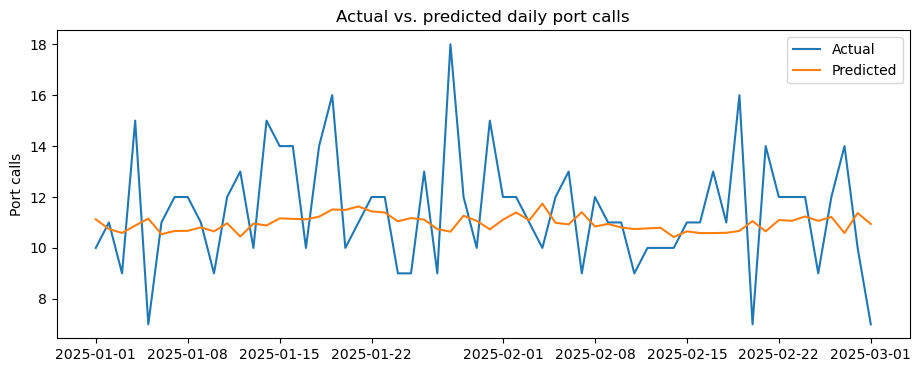

In [16]:
plt.figure(figsize=(11, 4))
plt.plot(test["date"].iloc[:60], actual.iloc[:60], label="Actual")
plt.plot(test["date"].iloc[:60], predicted[:60], label="Predicted")
plt.title("Actual vs. predicted daily port calls")
plt.ylabel("Port calls")
plt.legend()
plt.show()

In [17]:
future_model = make_pipeline(StandardScaler(), PoissonRegressor(alpha=best_alpha, max_iter=1000))
future_model.fit(data[features], data["portcalls"])

next_date = df["date"].max() + pd.Timedelta(days=1)
next_features = pd.DataFrame([{
    "lag_1": df["portcalls"].iloc[-1],
    "lag_7": df["portcalls"].iloc[-7],
    "avg_7": df["portcalls"].iloc[-7:].mean(),
    "month": next_date.month
}])

display(next_features)
forecast = future_model.predict(next_features)[0]
print("Forecast date:", next_date.date())
print("Predicted expected port calls:", round(forecast, 2))
print("Rounded vessel count:", round(forecast))

,lag_1,lag_7,avg_7,month
0,11,12,11.857143,7


Forecast date: 2026-07-18
Predicted expected port calls: 11.1
Rounded vessel count: 11


# SHAP

In [19]:
%pip install shap

   ---------------------------------------- 0.0/751.9 kB ? eta -:--:--
   ---------------------------------------- 0.0/751.9 kB ? eta -:--:--
   ---------------------------------------- 0.0/751.9 kB ? eta -:--:--
   ------------- -------------------------- 262.1/751.9 kB ? eta -:--:--
   ------------- -------------------------- 262.1/751.9 kB ? eta -:--:--
   -------------------------- ----------- 524.3/751.9 kB 524.4 kB/s eta 0:00:01
   -------------------------- ----------- 524.3/751.9 kB 524.4 kB/s eta 0:00:01
   -------------------------- ----------- 524.3/751.9 kB 524.4 kB/s eta 0:00:01
   -------------------------- ----------- 524.3/751.9 kB 524.4 kB/s eta 0:00:01
   ---------------------------------------- 751.9/751.9 kB 408.5 kB/s  0:00:01

   ---------------------------------------- 0/4 [tqdm]
   -------------------- ------------------- 2/4 [cloudpickle]
   ------------------------------ --------- 3/4 [shap]
   ------------------------------ --------- 3/4 [shap]
   -----------

  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.


c:\Users\achin\miniconda3\envs\ml_env\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


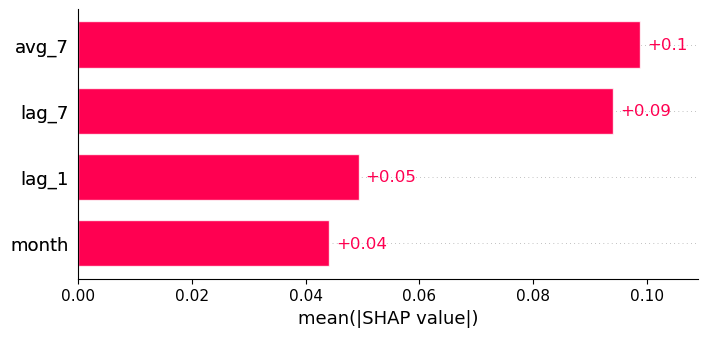

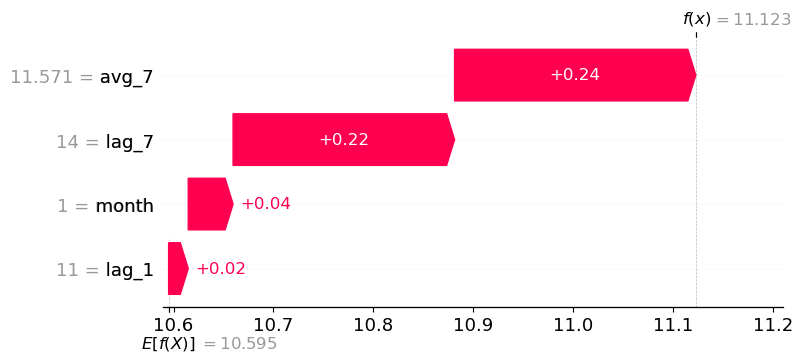

In [20]:

import shap
background = train_valid[features].sample(30, random_state=42)
explainer = shap.Explainer(model.predict, shap.maskers.Independent(background), algorithm="permutation")
values = explainer(test[features].iloc[:10], max_evals=2*len(features)+1)
shap.plots.bar(values)
shap.plots.waterfall(values[0])